In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans

## 사이킷런에서 제공하는 데이터를 이용하는 k평균 클러스터링

make_blobs() 메소드로 사이킷런이 제공하는 모든 방향을 같은 성질을 가지는 등방성 가우시안 정규 분포를 따르는 데이터를 랜덤하게 만들어준다.  
`n_samples`의 기본값은 100이고 랜덤하게 만들 데이터 개수를 지정한다.  
`n_features`의 기본값은 2이고 랜덤하게 만들 데이터당 피처의 개수를 지정한다.  
`centers`는 데이터를 랜덤하게 만들 때 클러스터의 개수를 설정해서 클러스터링용 가상 데이터를 만든다.

In [2]:
x_train, y_train = datasets.make_blobs(n_samples=100, n_features=2, centers=6, random_state=23)
print(x_train.shape, y_train.shape)

for i in range(len(x_train))[:5]:
    print(x_train[i], y_train[i])

(100, 2) (100,)
[0.88411964 9.75137075] 0
[ 1.94400074 -3.85864447] 4
[-1.50131409e-03  9.60939224e+00] 0
[ 5.92830926 -5.3446569 ] 1
[-6.40203141  2.12633259] 2


## k평균 클러스터링 적용 전 데이터 시각화

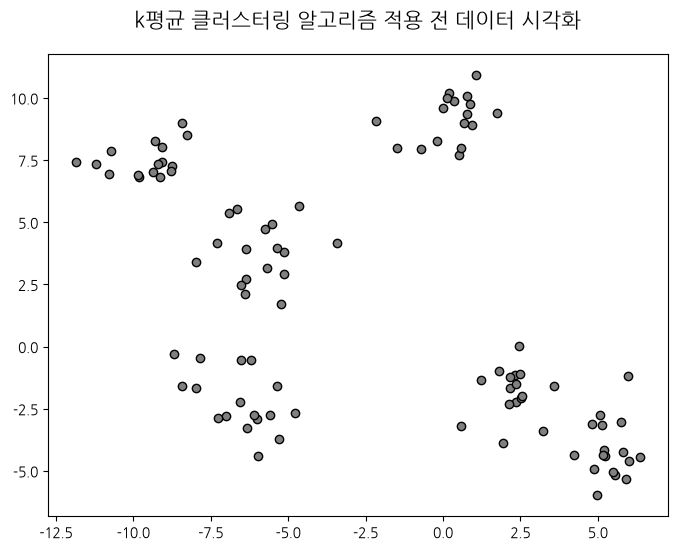

In [3]:
plt.figure(figsize=[8, 6])
plt.scatter(x_train[:, 0], x_train[:, 1], c='gray', edgecolors='black', marker='o')
plt.title('k평균 클러스터링 알고리즘 적용 전 데이터 시각화', pad=20, fontsize=15)
plt.show()

## k평균 클러스터링 모델을 만들고 학습 시킨다.

n_clusters에 군집화하려는 클러스터의 개수를 지정해서 k평균 클러스터링 모델을 만들고 군집화할 데이터를 넘겨서 학습시킨다.

In [4]:
model = KMeans(n_clusters=6)
model.fit(x_train)

KMeans(n_clusters=6)

## 각 클러스터의 중심과 데이터가 할당된 클러스터를 확인한다.

In [5]:
print(model.cluster_centers_)

[[ 5.38910591 -4.13134578]
 [-9.60201867  7.50431498]
 [ 0.24479554  9.17915425]
 [-6.5855826  -2.17854277]
 [-5.90617195  3.8084214 ]
 [ 2.2475036  -1.84685328]]


In [6]:
print(model.labels_)

[2 5 2 0 4 3 3 4 0 4 4 2 4 1 0 1 2 5 5 1 5 0 2 3 3 4 3 3 4 5 5 2 4 0 5 4 2
 0 4 0 2 1 3 1 3 2 1 4 0 0 4 2 3 4 3 5 5 0 1 3 0 5 1 5 4 4 1 3 2 0 5 2 1 1
 5 3 5 4 3 0 0 3 2 2 5 5 1 1 1 3 3 2 1 4 2 0 0 1 2 0]


## 데이터프레임을 만들고 파생 변수를 만들고 각 데이터가 할당된 클러스터를 넣어준다.

In [7]:
df = pd.DataFrame(x_train, columns=['x', 'y'])
df['label_1'] = y_train # make_blobs() 메소드를 실행해서 얻은 클러스터의 중심
df['label_2'] = model.labels_ # k평균 클러스터링 알고리즘으로 얻은 클러스터의 중심
df.head(20)

,x,y,label_1,label_2
0,0.884120,9.751371,0,2
1,1.944001,-3.858644,4,5
2,-0.001501,9.609392,0,2
3,5.928309,-5.344657,1,0
4,-6.402031,2.126333,2,4
5,-6.206620,-0.533699,3,3
6,-6.003600,-2.896963,3,3
7,-7.302346,4.185701,2,4
8,6.012819,-4.620225,1,0
9,-6.374456,2.712907,2,4


In [8]:
print(set(df.label_1), set(df.label_2))

{0, 1, 2, 3, 4, 5} {0, 1, 2, 3, 4, 5}


## k평균 클러스터링 적용 후 데이터 시각화

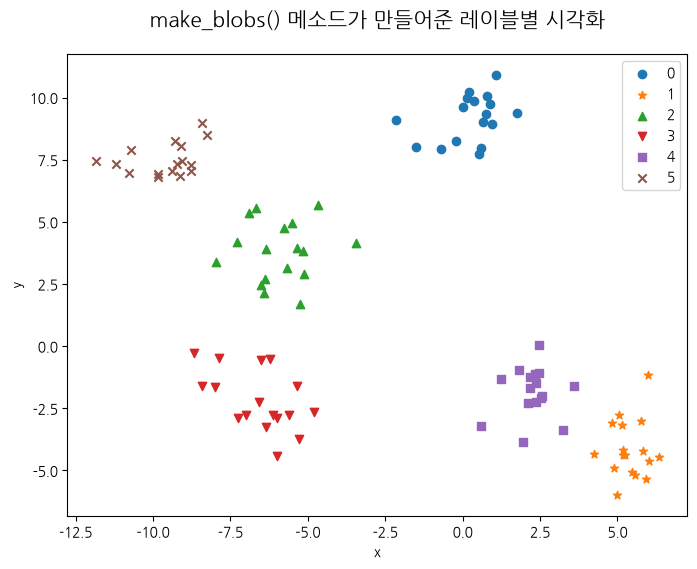

In [9]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for index, marker in enumerate(markers):
    df_index = df[df.label_1 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('make_blobs() 메소드가 만들어준 레이블별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

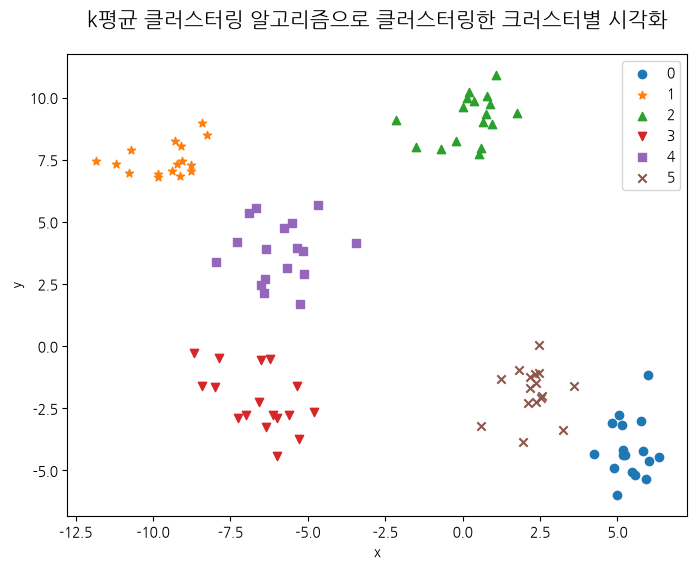

In [10]:
plt.figure(figsize=[8, 6])
markers = ['o', '*', '^', 'v', 's', 'x']

for index, marker in enumerate(markers):
    df_index = df[df.label_2 == index]
    plt.scatter(x=df_index.x, y=df_index.y, label=index, marker=marker)

plt.title('k평균 클러스터링 알고리즘으로 클러스터링한 크러스터별 시각화', pad=20, fontsize=15)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 모델을 평가한다.

실루엣 스코어는 서로 다른 군집이 얼마나 잘 분리되어 있는지를 나타내는 평가 지표로서 군집 문제에서 모델의 성능을 평가한다.  
실루엣 스코어는 -1 ~ 1 사이의 값을 가지며 점수가 높을수록 좋은 성능임을 의미한다.  

silhouette_score() 함수에 피처와 군집화 결과로 얻은 클러스터를 넘겨서 실루엣 스코어를 계산한다.

In [11]:
score = silhouette_score(x_train, model.labels_)
print(score)

0.6580963691356235
